In [4]:
import dezero as dz
import dezero.functions as F
import numpy as np
import matplotlib.pyplot as plt

$
\mathbb{y} = W\mathbb{x}+ b + \epsilon
$

$
\epsilon \sim N(0,1)
$

In [7]:
np.random.seed(0)
xdata = np.random.rand(100, 1)
ydata = 5 + 2 * xdata + np.random.randn(100, 1)
x, y = dz.variable(xdata), dz.variable(ydata)

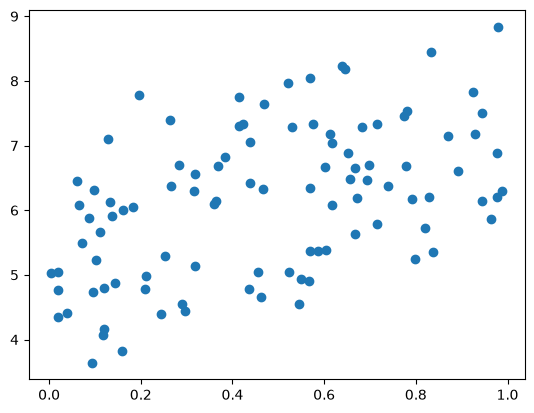

In [8]:
%matplotlib inline
plt.plot(xdata, ydata, 'o')

In [18]:
x, y

(<class 'dezero.core.Variable'>{
     data=array([[0.5488135 ],
                 [0.71518937],
                 [0.60276338],
                 [0.54488318],
                 [0.4236548 ],
                 [0.64589411],
                 [0.43758721],
                 [0.891773  ],
                 [0.96366276],
                 [0.38344152],
                 [0.79172504],
                 [0.52889492],
                 [0.56804456],
                 [0.92559664],
                 [0.07103606],
                 [0.0871293 ],
                 [0.0202184 ],
                 [0.83261985],
                 [0.77815675],
                 [0.87001215],
                 [0.97861834],
                 [0.79915856],
                 [0.46147936],
                 [0.78052918],
                 [0.11827443],
                 [0.63992102],
                 [0.14335329],
                 [0.94466892],
                 [0.52184832],
                 [0.41466194],
                 [0.26455561],
      

In [9]:
W = dz.variable(np.zeros((1,1)), name="W")
b = dz.variable(np.zeros(1), "b")
def predict(x):
    y = F.matmul(x, W) + b
    return y

# learning rate
lr = 0.1
iters = 100

losses = []
for i in range(iters):
    y_pred = predict(x)
    loss = F.mean_squared_error(y_pred, y)
    loss.name = "loss"
    
    W.cleargrad()
    b.cleargrad()
    loss.backward()

    W.data -= lr * W.grad.data
    b.data -= lr * b.grad.data
    losses.append(loss.data.squeeze())

## Optimizer

**SGD**:
- $\mathbb{w}_{t+1} = \mathbb{w}_{t} - \epsilon \frac{\partial L}{\partial \mathbb{w}}$

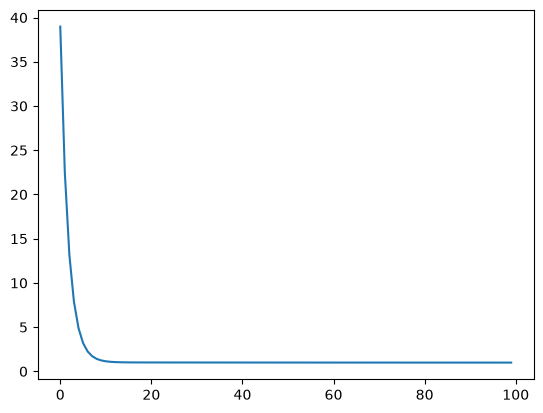

In [10]:
%matplotlib inline

plt.plot(range(iters), losses)